In [1]:


from google.colab import drive
import os

drive.mount("/content/drive")

data_folder = "/content/drive/MyDrive/LendingClub_Project/cleaned_data"

print("Folder exists:", os.path.exists(data_folder))
print("Files:", os.listdir(data_folder) if os.path.exists(data_folder) else "Not found")


Mounted at /content/drive
Folder exists: True
Files: ['lending_club_train.parquet', 'lending_club_test.parquet']


In [2]:



import pandas as pd

train_df = pd.read_parquet(
    os.path.join(data_folder, "lending_club_train.parquet")
)

test_df = pd.read_parquet(
    os.path.join(data_folder, "lending_club_test.parquet")
)

print("Training rows and columns:", train_df.shape)
print("Testing rows and columns:", test_df.shape)

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nMissing values in training:", train_df.isna().sum().sum())
print("Missing values in testing:", test_df.isna().sum().sum())


Training rows and columns: (1076280, 25)
Testing rows and columns: (269070, 25)

Training columns:
['loan_amnt', 'term', 'int_rate', 'installment', 'sub_grade', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'purpose', 'addr_state', 'dti', 'delinq_2yrs', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'mort_acc', 'pub_rec_bankruptcies', 'credit_history_months', 'target']

Missing values in training: 0
Missing values in testing: 0


In [1]:



target_counts = train_df["target"].value_counts().sort_index()
target_percentages = (
    train_df["target"].value_counts(normalize=True).sort_index() * 100
)

target_summary = pd.DataFrame({
    "Number of Loans": target_counts,
    "Percentage (%)": target_percentages.round(2)
})

target_summary.index = ["Fully Paid (0)", "Default / Charged Off (1)"]

display(target_summary)


NameError: name 'train_df' is not defined

In [2]:

# Reload Stage 4 training data

import pandas as pd
import os

data_folder = "/content/drive/MyDrive/LendingClub_Project/cleaned_data"

train_df = pd.read_parquet(
    os.path.join(data_folder, "lending_club_train.parquet")
)

print("Training data loaded:", train_df.shape)


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/LendingClub_Project/cleaned_data/lending_club_train.parquet'

In [3]:

from google.colab import drive

drive.mount("/content/drive")

import os

data_folder = "/content/drive/MyDrive/LendingClub_Project/cleaned_data"

print("Folder exists:", os.path.exists(data_folder))
print("Files:", os.listdir(data_folder) if os.path.exists(data_folder) else "Folder not found")


Mounted at /content/drive
Folder exists: True
Files: ['lending_club_train.parquet', 'lending_club_test.parquet']


In [4]:

# Reload training data for Stage 4

import pandas as pd

train_df = pd.read_parquet(
    "/content/drive/MyDrive/LendingClub_Project/cleaned_data/lending_club_train.parquet"
)

print("Training data loaded:", train_df.shape)


Training data loaded: (1076280, 25)


In [5]:



target_counts = train_df["target"].value_counts().sort_index()

target_percentages = (
    train_df["target"].value_counts(normalize=True).sort_index() * 100
)

target_summary = pd.DataFrame({
    "Number of Loans": target_counts,
    "Percentage (%)": target_percentages.round(2)
})

target_summary.index = [
    "Fully Paid (0)",
    "Default / Charged Off (1)"
]

display(target_summary)


,Number of Loans,Percentage (%)
Fully Paid (0),861401,80.04
Default / Charged Off (1),214879,19.96


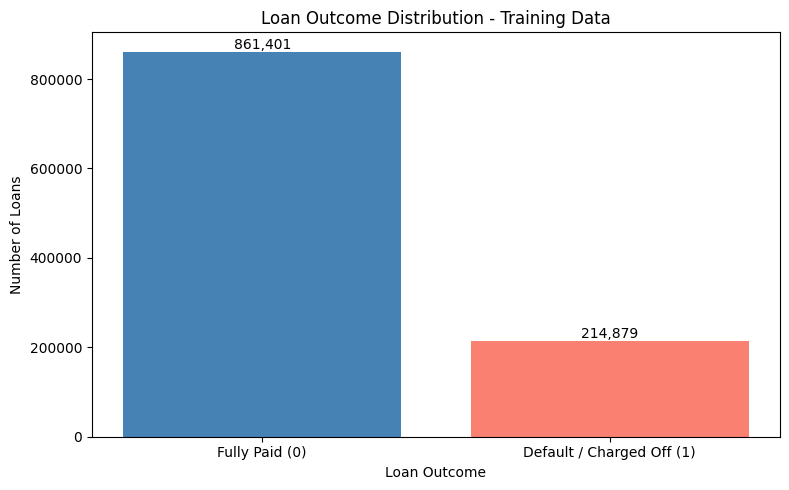

In [6]:


import matplotlib.pyplot as plt

labels = ["Fully Paid (0)", "Default / Charged Off (1)"]
counts = target_counts.values

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, counts, color=["steelblue", "salmon"])

plt.title("Loan Outcome Distribution - Training Data")
plt.xlabel("Loan Outcome")
plt.ylabel("Number of Loans")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


In [1]:



import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(train_df["loan_amnt"], bins=30, edgecolor="black")

plt.title("Distribution of Loan Amounts - Training Data")
plt.xlabel("Loan Amount ($)")
plt.ylabel("Number of Loans")

plt.tight_layout()
plt.show()

print("Loan amount statistics:")
print(train_df["loan_amnt"].describe())


NameError: name 'train_df' is not defined

<Figure size 900x500 with 0 Axes>

In [2]:



from google.colab import drive
import pandas as pd

drive.mount("/content/drive")

train_df = pd.read_parquet(
    "/content/drive/MyDrive/LendingClub_Project/cleaned_data/lending_club_train.parquet"
)

print("Training data loaded:", train_df.shape)


Mounted at /content/drive
Training data loaded: (1076280, 25)


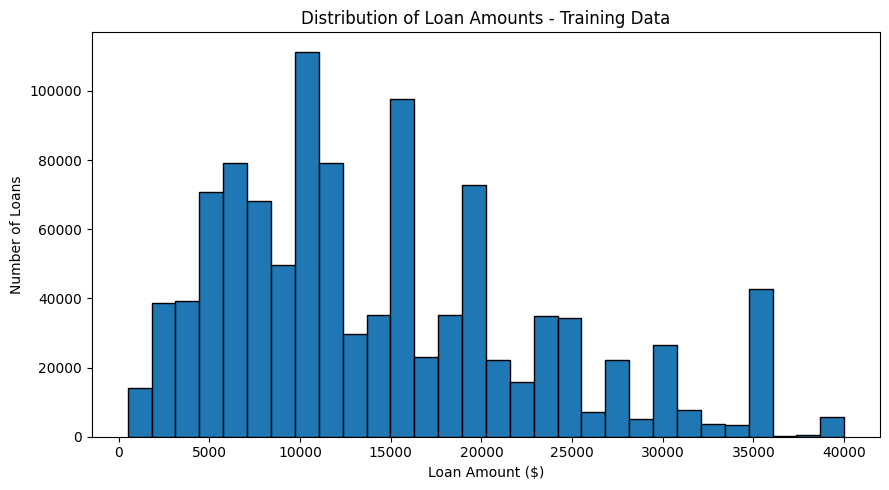

Loan amount statistics:
count    1.076280e+06
mean     1.442158e+04
std      8.720808e+03
min      5.000000e+02
25%      8.000000e+03
50%      1.200000e+04
75%      2.000000e+04
max      4.000000e+04
Name: loan_amnt, dtype: float64


In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(train_df["loan_amnt"], bins=30, edgecolor="black")

plt.title("Distribution of Loan Amounts - Training Data")
plt.xlabel("Loan Amount ($)")
plt.ylabel("Number of Loans")

plt.tight_layout()
plt.show()

print("Loan amount statistics:")
print(train_df["loan_amnt"].describe())

Annual income statistics:
count    1.076280e+06
mean     7.624681e+04
std      6.916469e+04
min      0.000000e+00
25%      4.590000e+04
50%      6.500000e+04
75%      9.000000e+04
max      9.550000e+06
Name: annual_inc, dtype: float64


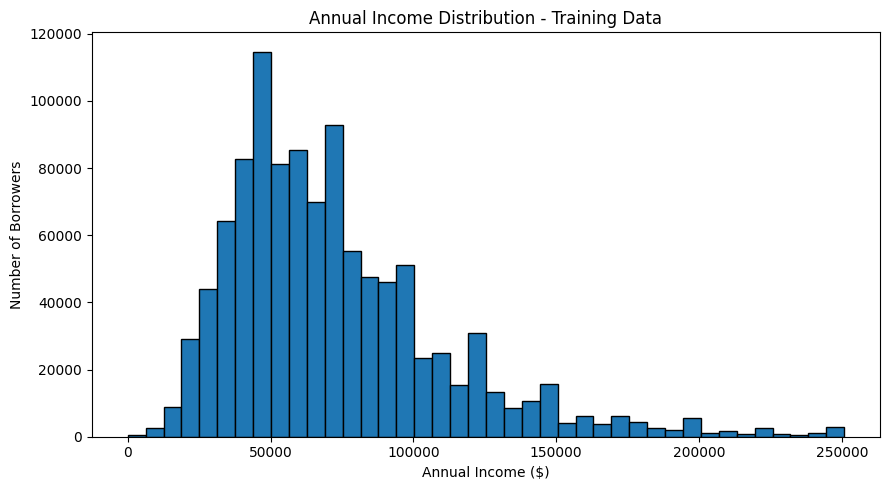


99th percentile: 250854.18


In [4]:

import matplotlib.pyplot as plt

print("Annual income statistics:")
print(train_df["annual_inc"].describe())


income_limit = train_df["annual_inc"].quantile(0.99)

plt.figure(figsize=(9, 5))

plt.hist(
    train_df.loc[train_df["annual_inc"] <= income_limit, "annual_inc"],
    bins=40,
    edgecolor="black"
)

plt.title("Annual Income Distribution - Training Data")
plt.xlabel("Annual Income ($)")
plt.ylabel("Number of Borrowers")

plt.tight_layout()
plt.show()

print("\n99th percentile:", round(income_limit, 2))


Interest rate statistics:
count    1.076280e+06
mean     1.324098e+01
std      4.769108e+00
min      5.310000e+00
25%      9.750000e+00
50%      1.274000e+01
75%      1.599000e+01
max      3.099000e+01
Name: int_rate, dtype: float64


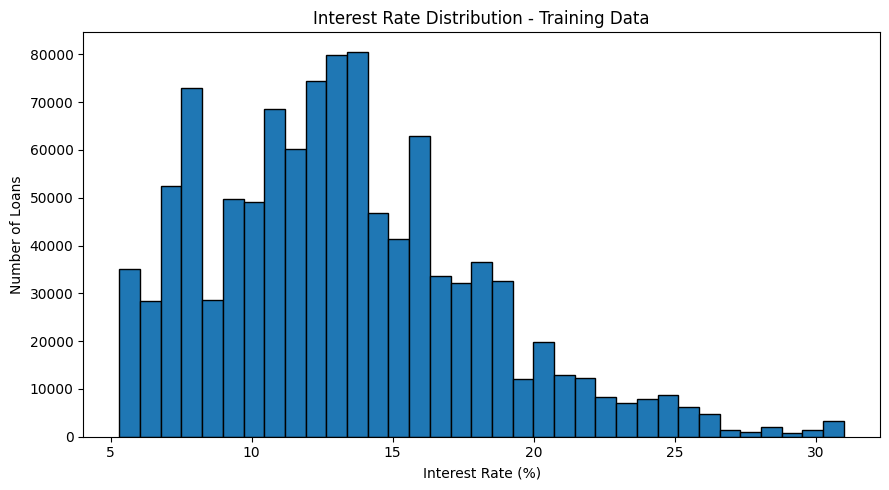

In [5]:



import matplotlib.pyplot as plt

print("Interest rate statistics:")
print(train_df["int_rate"].describe())

plt.figure(figsize=(9, 5))

plt.hist(
    train_df["int_rate"],
    bins=35,
    edgecolor="black"
)

plt.title("Interest Rate Distribution - Training Data")
plt.xlabel("Interest Rate (%)")
plt.ylabel("Number of Loans")

plt.tight_layout()
plt.show()


,count,default_rate_pct
int_rate,,
0–10%,300258,8.14
10–15%,442958,18.59
15–20%,247485,29.56
20–25%,64531,38.53
25–35%,21048,47.94


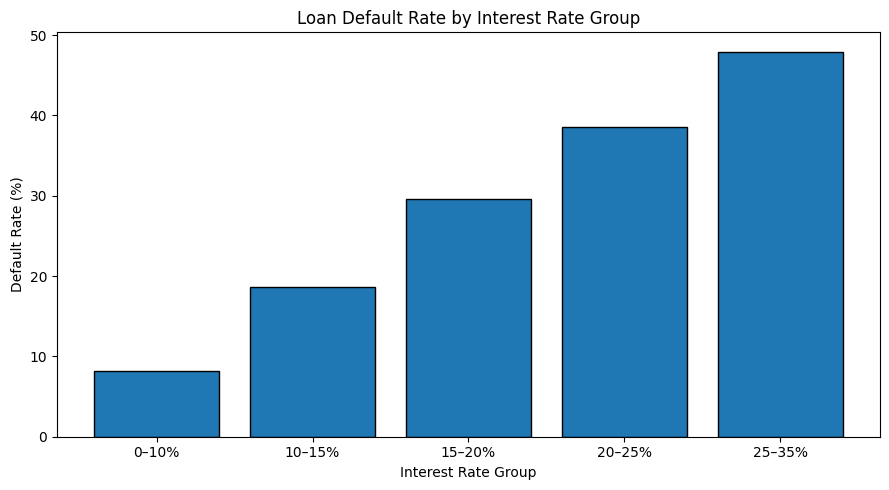

In [6]:

# Stage 4.4 - Interest Rate vs Loan Default

import pandas as pd
import matplotlib.pyplot as plt

# Divide interest rates into groups
interest_groups = pd.cut(
    train_df["int_rate"],
    bins=[0, 10, 15, 20, 25, 35],
    labels=["0–10%", "10–15%", "15–20%", "20–25%", "25–35%"],
    include_lowest=True
)

# Calculate default rate for each group
interest_default = (
    train_df.groupby(interest_groups, observed=True)["target"]
    .agg(["count", "mean"])
)

interest_default["default_rate_pct"] = (
    interest_default["mean"] * 100
).round(2)

display(interest_default[["count", "default_rate_pct"]])

# Draw the chart
plt.figure(figsize=(9, 5))
plt.bar(
    interest_default.index.astype(str),
    interest_default["default_rate_pct"],
    edgecolor="black"
)

plt.title("Loan Default Rate by Interest Rate Group")
plt.xlabel("Interest Rate Group")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.show()


,count,default_rate_pct
annual_inc,,
$0–30k,79458,24.34
$30k–50k,266863,22.49
$50k–75k,329490,20.49
$75k–100k,200237,18.21
Above $100k,200232,15.75


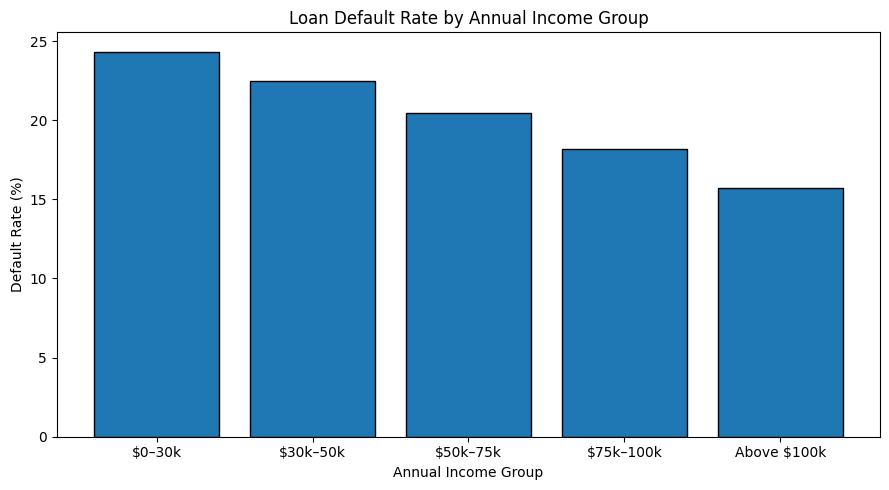

In [7]:

# Stage 4.4 - Annual Income vs Loan Default

import pandas as pd
import matplotlib.pyplot as plt

# Create annual income groups
income_groups = pd.cut(
    train_df["annual_inc"],
    bins=[-1, 30000, 50000, 75000, 100000, float("inf")],
    labels=[
        "$0–30k",
        "$30k–50k",
        "$50k–75k",
        "$75k–100k",
        "Above $100k"
    ]
)

# Calculate default rate for each income group
income_default = (
    train_df.groupby(income_groups, observed=True)["target"]
    .agg(["count", "mean"])
)

income_default["default_rate_pct"] = (
    income_default["mean"] * 100
).round(2)

display(income_default[["count", "default_rate_pct"]])

# Draw the chart
plt.figure(figsize=(9, 5))

plt.bar(
    income_default.index.astype(str),
    income_default["default_rate_pct"],
    edgecolor="black"
)

plt.title("Loan Default Rate by Annual Income Group")
plt.xlabel("Annual Income Group")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.show()


,count,default_rate_pct
loan_amnt,,
$0–5k,145763,15.72
$5k–10k,298709,17.23
$10k–15k,226971,20.82
$15k–20k,171311,22.65
$20k–30k,168347,22.88
$30k–40k,65179,24.43


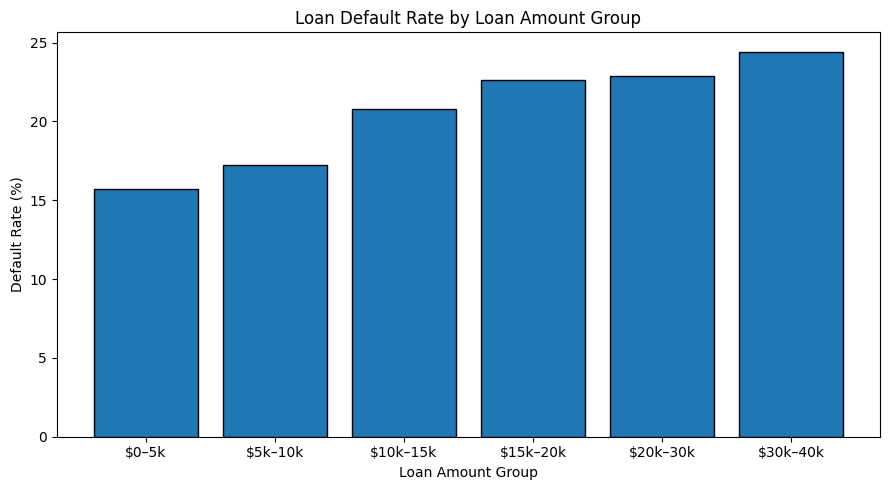

In [8]:

# Stage 4.4 - Loan Amount vs Loan Default

import pandas as pd
import matplotlib.pyplot as plt

# Divide loan amounts into groups
loan_groups = pd.cut(
    train_df["loan_amnt"],
    bins=[0, 5000, 10000, 15000, 20000, 30000, 40000],
    labels=[
        "$0–5k",
        "$5k–10k",
        "$10k–15k",
        "$15k–20k",
        "$20k–30k",
        "$30k–40k"
    ],
    include_lowest=True
)

# Calculate default rate within each group
loan_default = (
    train_df.groupby(loan_groups, observed=True)["target"]
    .agg(["count", "mean"])
)

loan_default["default_rate_pct"] = (
    loan_default["mean"] * 100
).round(2)

display(loan_default[["count", "default_rate_pct"]])

# Create chart
plt.figure(figsize=(9, 5))

plt.bar(
    loan_default.index.astype(str),
    loan_default["default_rate_pct"],
    edgecolor="black"
)

plt.title("Loan Default Rate by Loan Amount Group")
plt.xlabel("Loan Amount Group")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()


In [9]:



print("Training records:", len(train_df))

print(
    "Borrowers with zero annual income:",
    (train_df["annual_inc"] == 0).sum()
)

print(
    "Borrowers with negative annual income:",
    (train_df["annual_inc"] < 0).sum()
)

print(
    "Missing annual income values:",
    train_df["annual_inc"].isna().sum()
)


Training records: 1076280
Borrowers with zero annual income: 282
Borrowers with negative annual income: 0
Missing annual income values: 0


In [10]:

# Stage 4.5 - Loan-to-Income Feature Engineering

import numpy as np

# Keep the original training data unchanged
train_fe = train_df.copy()

# Flag borrowers with zero reported income
train_fe["zero_income_flag"] = (
    train_fe["annual_inc"] == 0
).astype(int)

# Calculate ratio only when income is positive
train_fe["loan_to_income_ratio"] = (
    train_fe["loan_amnt"] /
    train_fe["annual_inc"].where(train_fe["annual_inc"] > 0)
)

# Replace undefined ratios with training median
ratio_median = train_fe["loan_to_income_ratio"].median()

train_fe["loan_to_income_ratio"] = (
    train_fe["loan_to_income_ratio"].fillna(ratio_median)
)

print("New training shape:", train_fe.shape)
print("Zero-income flags:", train_fe["zero_income_flag"].sum())
print("Median ratio used:", round(ratio_median, 4))
print("Missing ratios:", train_fe["loan_to_income_ratio"].isna().sum())
print("Infinite ratios:", np.isinf(train_fe["loan_to_income_ratio"]).sum())

print("\nLoan-to-income ratio statistics:")
print(train_fe["loan_to_income_ratio"].describe())


New training shape: (1076280, 27)
Zero-income flags: 282
Median ratio used: 0.2
Missing ratios: 0
Infinite ratios: 0

Loan-to-income ratio statistics:
count    1.076280e+06
mean     4.345176e-01
std      7.879831e+01
min      1.714286e-04
25%      1.246883e-01
50%      2.000000e-01
75%      2.909091e-01
max      4.000000e+04
Name: loan_to_income_ratio, dtype: float64


In [11]:

# Stage 4.5 - Inspect extreme loan-to-income ratios

print("Loan-to-income ratio percentiles:")
print(
    train_fe["loan_to_income_ratio"].quantile(
        [0.50, 0.90, 0.95, 0.99, 0.999, 1.00]
    )
)

print("\nRatios above 1:",
      (train_fe["loan_to_income_ratio"] > 1).sum())

print("Ratios above 10:",
      (train_fe["loan_to_income_ratio"] > 10).sum())

print("\nTop 10 highest ratios:")
display(
    train_fe[
        ["loan_amnt", "annual_inc", "loan_to_income_ratio"]
    ].sort_values(
        "loan_to_income_ratio",
        ascending=False
    ).head(10)
)


Loan-to-income ratio percentiles:
0.500        0.200000
0.900        0.377358
0.950        0.428571
0.990        0.500000
0.999        1.066667
1.000    40000.000000
Name: loan_to_income_ratio, dtype: float64

Ratios above 1: 1203
Ratios above 10: 66

Top 10 highest ratios:


,loan_amnt,annual_inc,loan_to_income_ratio
236571,40000.0,1.0,40000.0
119332,40000.0,1.0,40000.0
795297,35000.0,1.0,35000.0
513421,30000.0,1.0,30000.0
227084,24000.0,1.0,24000.0
317029,18000.0,1.0,18000.0
271796,15000.0,1.0,15000.0
927248,11000.0,1.0,11000.0
733631,15000.0,2.0,7500.0
205786,6000.0,1.0,6000.0


In [12]:

# Stage 4.5 - Cap extreme loan-to-income ratios

# Save the original ratio for comparison
train_fe["loan_to_income_ratio_original"] = (
    train_fe["loan_to_income_ratio"]
)

# Calculate upper limit from training data only
ratio_cap = train_fe["loan_to_income_ratio"].quantile(0.99)

# Cap the engineered ratio
train_fe["loan_to_income_ratio"] = (
    train_fe["loan_to_income_ratio"].clip(upper=ratio_cap)
)

print("Cap value:", round(ratio_cap, 4))

print(
    "Values affected:",
    (train_fe["loan_to_income_ratio_original"] > ratio_cap).sum()
)

print(
    "Maximum ratio after capping:",
    train_fe["loan_to_income_ratio"].max()
)

print(
    "Missing ratios:",
    train_fe["loan_to_income_ratio"].isna().sum()
)


Cap value: 0.5
Values affected: 7822
Maximum ratio after capping: 0.5
Missing ratios: 0


In [13]:

# Stage 4.5 - Apply feature engineering to test data

import pandas as pd
import numpy as np

test_df = pd.read_parquet(
    "/content/drive/MyDrive/LendingClub_Project/cleaned_data/lending_club_test.parquet"
)

test_fe = test_df.copy()

# Create zero-income flag
test_fe["zero_income_flag"] = (
    test_fe["annual_inc"] == 0
).astype(int)

# Calculate ratio safely
test_fe["loan_to_income_ratio"] = (
    test_fe["loan_amnt"] /
    test_fe["annual_inc"].where(test_fe["annual_inc"] > 0)
)

# Use values learned from training only
test_fe["loan_to_income_ratio"] = (
    test_fe["loan_to_income_ratio"]
    .fillna(ratio_median)
    .clip(upper=ratio_cap)
)

# Remove the temporary comparison column from training
train_fe = train_fe.drop(
    columns=["loan_to_income_ratio_original"]
)

print("Training shape:", train_fe.shape)
print("Testing shape:", test_fe.shape)
print("Same columns:", train_fe.columns.equals(test_fe.columns))
print("Training missing values:", train_fe.isna().sum().sum())
print("Testing missing values:", test_fe.isna().sum().sum())
print("Testing infinite ratios:", np.isinf(test_fe["loan_to_income_ratio"]).sum())


Training shape: (1076280, 27)
Testing shape: (269070, 27)
Same columns: True
Training missing values: 0
Testing missing values: 0
Testing infinite ratios: 0


In [14]:

# Stage 4.5 - Save feature-engineered datasets

import os

stage4_folder = "/content/drive/MyDrive/LendingClub_Project/stage4_data"

os.makedirs(stage4_folder, exist_ok=True)

train_path = os.path.join(
    stage4_folder, "lending_club_train_stage4.parquet"
)

test_path = os.path.join(
    stage4_folder, "lending_club_test_stage4.parquet"
)

train_fe.to_parquet(train_path, index=False)
test_fe.to_parquet(test_path, index=False)

print("Training file saved:", os.path.exists(train_path))
print("Testing file saved:", os.path.exists(test_path))
print("Saved files:", os.listdir(stage4_folder))


Training file saved: True
Testing file saved: True
Saved files: ['lending_club_train_stage4.parquet', 'lending_club_test_stage4.parquet']
